<a href="https://colab.research.google.com/github/curtismutuma-rgb/AI-for-Science-and-Engineering-Short-Course/blob/main/Week6_Clustering_ChestMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unsupervised Clustering of Chest X-ray Images

This notebook continues the medical disease-identification project with ChestMNIST. It uses **K-means clustering** to group images by simple pixel-intensity characteristics. The pneumonia label is excluded from clustering and is used only afterward to help describe the groups. This is an educational exploration, not a diagnostic method.


## Features selected for clustering

I will investigate two numerical features derived from each 28 × 28 grayscale chest X-ray:

- **Mean pixel intensity:** average image brightness.
- **Pixel-intensity standard deviation:** spread of pixel values within an image, used as a simple contrast measure.

K-means uses distance, so I will standardize these features before clustering. The pneumonia label will **not** be used as an input feature; after clustering, I will summarize its share in each group only as a post-hoc comparison. The analysis uses a reproducible sample of up to 20,000 training images to keep the notebook responsive.


In [1]:
# Install the official MedMNIST package in the Colab runtime.
!pip -q install medmnist

In [2]:
# Import data, scaling, clustering, scoring, and plotting tools.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from medmnist import ChestMNIST, INFO
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Download the official training split of the ChestMNIST dataset.
train_data = ChestMNIST(split="train", download=True)
print(f"Official training images available: {len(train_data):,}")

# Derive one brightness and one contrast feature from every X-ray.
pixels = np.asarray(train_data.imgs).reshape(len(train_data), -1)
mean_intensity = pixels.mean(axis=1)
intensity_std = pixels.std(axis=1)

# Keep the pneumonia label aside for later description, not for clustering.
label_map = INFO["chestmnist"]["label"]
label_names = [label_map[str(i)] for i in range(len(label_map))]
pneumonia_index = label_names.index("pneumonia")
label_matrix = np.asarray(train_data.labels).reshape(len(train_data), -1).astype(int)
pneumonia_label = label_matrix[:, pneumonia_index]

# Build a table, then draw a seeded sample for a fast and repeatable analysis.
all_features = pd.DataFrame({
    "mean_pixel_intensity": mean_intensity,
    "pixel_intensity_std": intensity_std,
    "pneumonia_label": pneumonia_label,
})
sample_size = min(20000, len(all_features))
analysis_df = all_features.sample(n=sample_size, random_state=42).reset_index(drop=True)
display(analysis_df.head())
print(f"Images selected for clustering: {len(analysis_df):,}")
print("Pneumonia label is retained for post-hoc description only.")

100%|██████████| 82.8M/82.8M [01:07<00:00, 1.23MB/s]


Official training images available: 78,468


,mean_pixel_intensity,pixel_intensity_std,pneumonia_label
0,106.429847,47.488346,0
1,161.709184,60.785375,0
2,110.535714,58.604205,1
3,104.673469,34.312943,0
4,133.977041,60.802767,0


Images selected for clustering: 20,000
Pneumonia label is retained for post-hoc description only.


,k,inertia,silhouette_score
0,2,23649.1427,0.3934
1,3,14139.1844,0.4504
2,4,11331.1210,0.3763
3,5,9253.6763,0.3758
4,6,7669.9681,0.3607
5,7,6754.1467,0.3495
6,8,6058.7689,0.3375


Selected number of clusters (highest silhouette score): k = 3


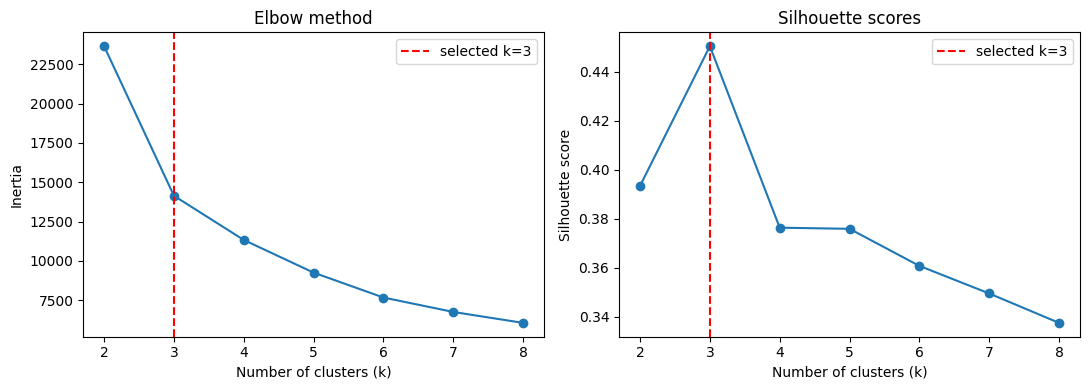

In [3]:
# Standardize the two clustering features so they contribute on comparable scales.
feature_columns = ["mean_pixel_intensity", "pixel_intensity_std"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(analysis_df[feature_columns])

# Fit K-means for several values of k and record inertia and silhouette score.
k_values = range(2, 9)
cluster_results = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    cluster_ids = kmeans.fit_predict(X_scaled)
    score = silhouette_score(
        X_scaled,
        cluster_ids,
        sample_size=min(2500, len(X_scaled)),
        random_state=42,
    )
    cluster_results.append({
        "k": k,
        "inertia": kmeans.inertia_,
        "silhouette_score": score,
    })

scores_df = pd.DataFrame(cluster_results)
display(scores_df.round(4))

# Select the k with the highest sampled silhouette score and inspect the elbow plot too.
selected_k = int(scores_df.loc[scores_df["silhouette_score"].idxmax(), "k"])
print(f"Selected number of clusters (highest silhouette score): k = {selected_k}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(scores_df["k"], scores_df["inertia"], marker="o")
axes[0].axvline(selected_k, color="red", linestyle="--", label=f"selected k={selected_k}")
axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[0].legend()
axes[1].plot(scores_df["k"], scores_df["silhouette_score"], marker="o")
axes[1].axvline(selected_k, color="red", linestyle="--", label=f"selected k={selected_k}")
axes[1].set(title="Silhouette scores", xlabel="Number of clusters (k)", ylabel="Silhouette score")
axes[1].legend()
plt.tight_layout()
plt.show()

## Selecting the number of clusters

The elbow plot shows how within-cluster variation (inertia) decreases as `k` increases; I look for a point where the decrease begins to level off. The silhouette score measures how well-separated the clusters are, with higher values generally indicating clearer separation. This notebook selects the `k` with the highest silhouette score among 2–8 and uses the elbow curve as a second check. Both are heuristics, so the selected clusters should also be interpretable.


,image_count,mean_brightness,average_within_image_std,pneumonia_label_share
cluster,,,,
0,5110,114.106,44.188,0.014
1,10004,116.339,63.373,0.012
2,4886,158.584,50.302,0.010


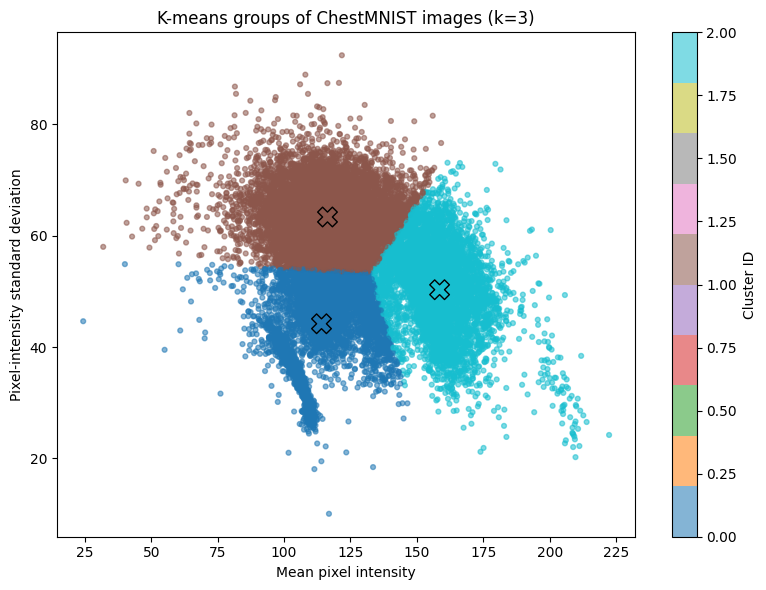

In [4]:
# Fit the final K-means model using the selected number of clusters.
final_model = KMeans(n_clusters=selected_k, n_init=10, random_state=42)
analysis_df["cluster"] = final_model.fit_predict(X_scaled)
cluster_centers = scaler.inverse_transform(final_model.cluster_centers_)

# Summarize the size and average feature values for each discovered group.
cluster_summary = analysis_df.groupby("cluster").agg(
    image_count=("cluster", "size"),
    mean_brightness=("mean_pixel_intensity", "mean"),
    average_within_image_std=("pixel_intensity_std", "mean"),
    pneumonia_label_share=("pneumonia_label", "mean"),
).round(3)
display(cluster_summary)

# Plot the clusters in the original feature space and mark their centers.
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    analysis_df["mean_pixel_intensity"],
    analysis_df["pixel_intensity_std"],
    c=analysis_df["cluster"],
    cmap="tab10",
    s=12,
    alpha=0.55,
    label="Images",
)
plt.scatter(
    cluster_centers[:, 0],
    cluster_centers[:, 1],
    marker="X",
    s=200,
    c=range(selected_k),
    cmap="tab10",
    edgecolor="black",
    label="Cluster centers",
)
plt.xlabel("Mean pixel intensity")
plt.ylabel("Pixel-intensity standard deviation")
plt.title(f"K-means groups of ChestMNIST images (k={selected_k})")
plt.colorbar(scatter, label="Cluster ID")
plt.tight_layout()
plt.show()

## Short discussion: what the clusters may represent

K-means groups images that have similar average brightness and contrast. The summary table and scatter plot show the characteristics of each group; the cluster IDs themselves have no ranking or medical meaning. These groups may reflect different image-intensity profiles, such as exposure, acquisition, or preprocessing differences, rather than distinct diseases. The pneumonia-label share is checked only after clustering: a difference between groups may suggest an association in this dataset, but it does not mean the clusters are pneumonia diagnoses or that image intensity causes disease.

The code below adds a brief data-based description using the cluster profiles calculated in this run.

In [5]:
# Generate a short data-based description of the cluster profiles.
brightest_cluster = cluster_summary["mean_brightness"].idxmax()
darkest_cluster = cluster_summary["mean_brightness"].idxmin()
highest_contrast_cluster = cluster_summary["average_within_image_std"].idxmax()
highest_label_share_cluster = cluster_summary["pneumonia_label_share"].idxmax()
discussion = (
    f"**Observed groups:** Cluster {brightest_cluster} has the highest mean brightness "
    f"({cluster_summary.loc[brightest_cluster, 'mean_brightness']:.2f}), while cluster {darkest_cluster} has the lowest "
    f"({cluster_summary.loc[darkest_cluster, 'mean_brightness']:.2f}). Cluster {highest_contrast_cluster} has the highest average "
    f"within-image intensity standard deviation ({cluster_summary.loc[highest_contrast_cluster, 'average_within_image_std']:.2f}). "
    f"The largest pneumonia-label share occurs in cluster {highest_label_share_cluster} "
    f"({cluster_summary.loc[highest_label_share_cluster, 'pneumonia_label_share']:.1%}). These patterns describe this sample only; "
    "the labels were not used to form clusters, and the groups should be interpreted as image-appearance profiles rather than diagnoses."
)
display(Markdown(discussion))

**Observed groups:** Cluster 2 has the highest mean brightness (158.58), while cluster 0 has the lowest (114.11). Cluster 1 has the highest average within-image intensity standard deviation (63.37). The largest pneumonia-label share occurs in cluster 0 (1.4%). These patterns describe this sample only; the labels were not used to form clusters, and the groups should be interpreted as image-appearance profiles rather than diagnoses.

## Submission reminder

Run all cells in Google Colab to download the dataset, compare values of `k`, fit the final clusters, and produce the plots and group descriptions. Save/download the completed `.ipynb`, upload it to your course-project GitHub repository, copy the notebook file's GitHub URL into Google Classroom, and click **Turn in**.